<a href="https://colab.research.google.com/github/alldi1212/tugasYOLO/blob/main/tugasYOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os
import urllib.request

# Buat direktori penyimpanan
os.makedirs('original_images', exist_ok=True)
os.makedirs('hasil_conf_rendah', exist_ok=True)
os.makedirs('hasil_conf_tinggi', exist_ok=True)

# 2. Daftar 5 sampel gambar uji publik (bisa diganti sesuai kebutuhan)
image_urls = [
    ("https://images.unsplash.com/photo-1543466835-00a7907e9de1", "gambar1.jpg"),
    ("https://images.unsplash.com/photo-1568605117036-5fe5e7bab0b7", "gambar2.jpg"),
    ("https://images.unsplash.com/photo-1574158622682-e40e69881006", "gambar3.jpg"),
    ("https://images.unsplash.com/photo-1555041469-a586c61ea9bc", "gambar4.jpg"),
    ("https://images.unsplash.com/photo-1503376780353-7e6692767b70", "gambar5.jpg")
]

image_paths = []
print("Mengunduh sampel gambar...")
for url, filename in image_urls:
    try:
        urllib.request.urlretrieve(url, filename)
        image_paths.append(filename)
        print(f"[BERHASIL] Mengunduh {filename}")
    except Exception as e:
        print(f"[GAGAL] Mengunduh {filename}: {e}")

print("Persiapan selesai. Gambar siap diproses.")

Mengunduh sampel gambar...
[BERHASIL] Mengunduh gambar1.jpg
[BERHASIL] Mengunduh gambar2.jpg
[BERHASIL] Mengunduh gambar3.jpg
[BERHASIL] Mengunduh gambar4.jpg
[BERHASIL] Mengunduh gambar5.jpg
Persiapan selesai. Gambar siap diproses.


=== MEMULAI PROSES DETEKSI OBJEK DI GOOGLE COLAB ===

MEMPROSES GAMBAR 1: gambar1.jpg

--- Log Objek (Threshold = 0.25) ---
  * Objek: dog        | Conf: 0.88 | BBox: [745.7, 373.7, 3037.5, 3020.2]

--- Log Objek (Threshold = 0.75) ---
  * Objek: dog        | Conf: 0.88 | BBox: [745.7, 373.7, 3037.5, 3020.2]


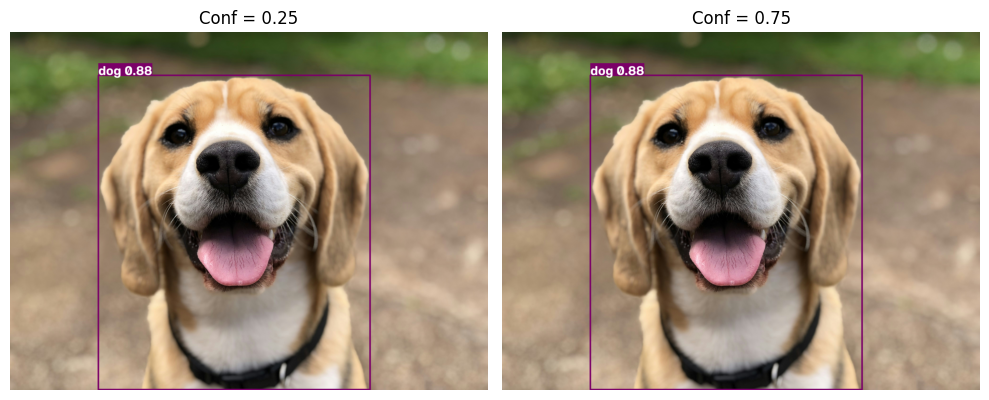


MEMPROSES GAMBAR 2: gambar2.jpg

--- Log Objek (Threshold = 0.25) ---
  * Objek: car        | Conf: 0.77 | BBox: [1947.5, 1447.7, 3433.7, 2377.0]

--- Log Objek (Threshold = 0.75) ---
  * Objek: car        | Conf: 0.77 | BBox: [1947.5, 1447.7, 3433.7, 2377.0]


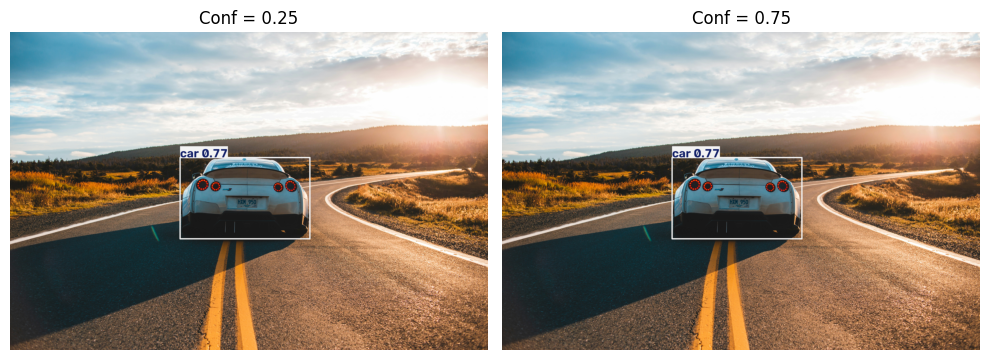


MEMPROSES GAMBAR 3: gambar3.jpg

--- Log Objek (Threshold = 0.25) ---
  * Objek: cat        | Conf: 0.89 | BBox: [198.3, 337.6, 2075.3, 2328.1]

--- Log Objek (Threshold = 0.75) ---
  * Objek: cat        | Conf: 0.89 | BBox: [198.3, 337.6, 2075.3, 2328.1]


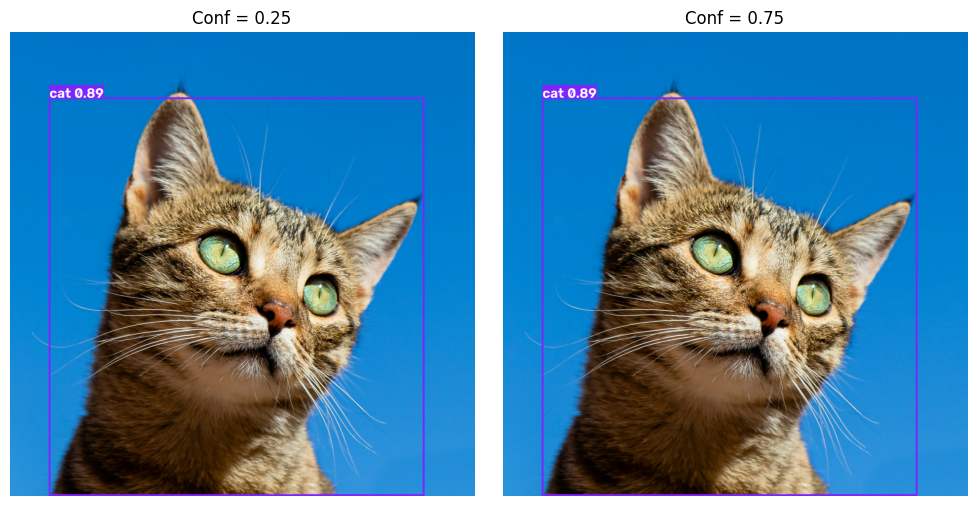


MEMPROSES GAMBAR 4: gambar4.jpg

--- Log Objek (Threshold = 0.25) ---
  * Objek: couch      | Conf: 0.84 | BBox: [635.1, 1442.3, 5186.4, 3144.9]

--- Log Objek (Threshold = 0.75) ---
  * Objek: couch      | Conf: 0.84 | BBox: [635.1, 1442.3, 5186.4, 3144.9]


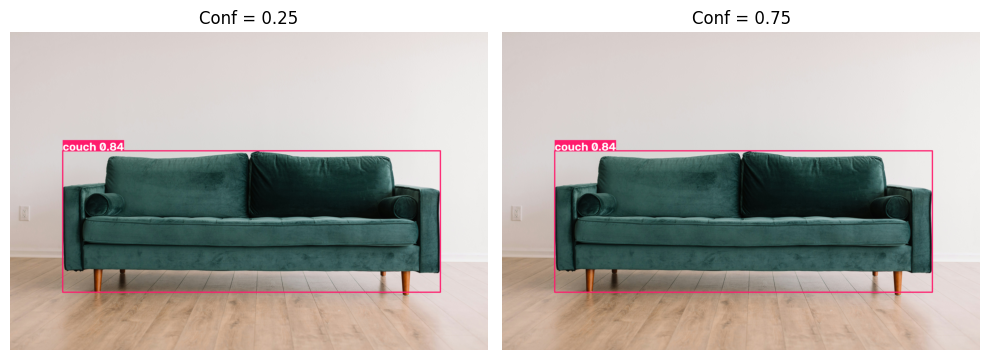


MEMPROSES GAMBAR 5: gambar5.jpg

--- Log Objek (Threshold = 0.25) ---
  * Objek: car        | Conf: 0.93 | BBox: [569.4, 766.2, 3201.6, 1926.6]
  * Objek: car        | Conf: 0.32 | BBox: [2896.5, 926.3, 3063.0, 998.8]

--- Log Objek (Threshold = 0.75) ---
  * Objek: car        | Conf: 0.93 | BBox: [569.4, 766.2, 3201.6, 1926.6]


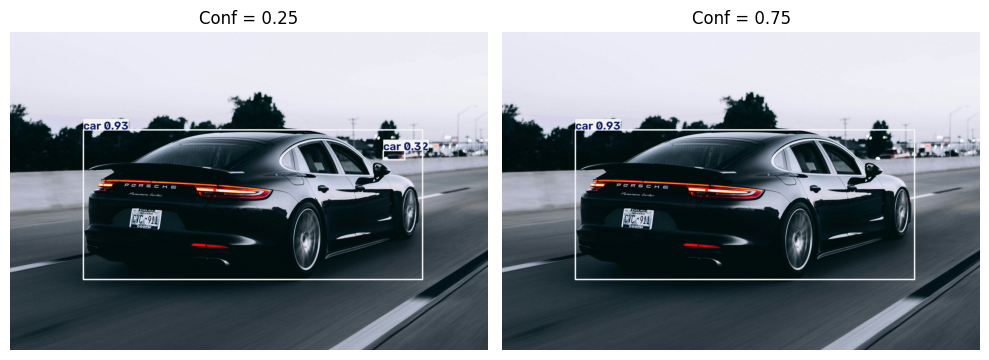


[SELESAI] Seluruh gambar berhasil diproses, dicatat, dan divisualisasikan.


In [6]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 1. Muat model pretrained YOLO (YOLOv8 nano)
model = YOLO('yolov8n.pt')

# 5. Tentukan dua nilai confidence threshold untuk perbandingan
conf_rendah = 0.25
conf_tinggi = 0.75

print("=== MEMULAI PROSES DETEKSI OBJEK DI GOOGLE COLAB ===")

for i, img_path in enumerate(image_paths, start=1):
    print(f"\n{'='*40}")
    print(f"MEMPROSES GAMBAR {i}: {img_path}")
    print(f"{'='*40}")

    img = cv2.imread(img_path)
    if img is None:
        print(f"[PERINGATAN] File {img_path} tidak ditemukan.")
        continue

    # 3. Simpan salinan gambar asli
    orig_save_path = os.path.join('original_images', f'orig_{i}.jpg')
    cv2.imwrite(orig_save_path, img)

    # Jalankan inferensi dengan Confidence Threshold Rendah (0.25)
    results_low = model(img_path, conf=conf_rendah, verbose=False)
    plotted_low = results_low[0].plot()
    cv2.imwrite(os.path.join('hasil_conf_rendah', f'deteksi_low_{i}.jpg'), plotted_low)

    # Jalankan inferensi dengan Confidence Threshold Tinggi (0.75)
    results_high = model(img_path, conf=conf_tinggi, verbose=False)
    plotted_high = results_high[0].plot()
    cv2.imwrite(os.path.join('hasil_conf_tinggi', f'deteksi_high_{i}.jpg'), plotted_high)

    # 4. Catat label, confidence, dan bounding box (Threshold Rendah)
    print(f"\n--- Log Objek (Threshold = {conf_rendah}) ---")
    for box in results_low[0].boxes:
        label = model.names[int(box.cls[0])]
        conf = float(box.conf[0])
        xyxy = [round(float(c), 1) for c in box.xyxy[0]]
        print(f"  * Objek: {label:<10} | Conf: {conf:.2f} | BBox: {xyxy}")

    # Catat label, confidence, dan bounding box (Threshold Tinggi)
    print(f"\n--- Log Objek (Threshold = {conf_tinggi}) ---")
    if len(results_high[0].boxes) == 0:
        print("  * Tidak ada objek yang memenuhi threshold tinggi ini.")
    for box in results_high[0].boxes:
        label = model.names[int(box.cls[0])]
        conf = float(box.conf[0])
        xyxy = [round(float(c), 1) for c in box.xyxy[0]]
        print(f"  * Objek: {label:<10} | Conf: {conf:.2f} | BBox: {xyxy}")

    # Tampilkan perbandingan visual langsung di notebook Colab
    img_low_rgb = cv2.cvtColor(plotted_low, cv2.COLOR_BGR2RGB)
    img_high_rgb = cv2.cvtColor(plotted_high, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_low_rgb)
    axes[0].set_title(f"Conf = {conf_rendah}")
    axes[0].axis('off')

    axes[1].imshow(img_high_rgb)
    axes[1].set_title(f"Conf = {conf_tinggi}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

print("\n[SELESAI] Seluruh gambar berhasil diproses, dicatat, dan divisualisasikan.")